# 03 — TCG vs the INPOP internal solution

**What this notebook does:** compares TEMPUS against the TCG−TCB series that INPOP distributes
*inside* its own ephemeris files, and quantifies how the residual depends on the dynamical
model and on the ephemeris release. It produces every INPOP-related number in the paper's
validation and sensitivity tables.

**Why this differs from notebooks 01/02.** Those compare TEMPUS against Klioner — another
*implementation* of the same model on the same ephemeris, so the residual measures the
transformation alone. Here the reference is the time scale INPOP itself derived while building
the ephemeris, from the full perturber set of its own fit. The two dynamical models are not
identical by construction, so the residual measures **how completely that model is reproduced**.

**Reference availability:** INPOP ships only TT−TDB and TCG−TCB as time ephemerides, so this
comparison is possible for the Earth alone. It is read straight from the ephemeris file with
`--out-tcg-tcb` (CALCEPH query). The equivalent INPOP distributed `.asc` export evaluates identically — that cross-check lives in `06_validation_chebyshev.ipynb` and is not repeated here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

from tempus import jd_split, jd_tt_to_tcb, jd_tt_to_tdb
from tempus.model import L_B, TimeGrid, jd_tcb_to_tdb
from tempus.output import read_csv
from nb_utils import DAY_S, plot_compare_2timescales, run_tempus_integration

eph_19a_tcb = Path("../data/ephem/inpop19a_TCB_m100_p100_tcg.dat").resolve()
eph_19a_tdb = Path("../data/ephem/inpop19a_TDB_m100_p100_tt.dat").resolve()
eph_21a_tcb = Path("../data/ephem/inpop21a_TCB_m100_p100_tcg.dat").resolve()
ast_file    = Path("../data/ephem/sim20201224Tyref13quar.dat").resolve() #inpop sim file we used at first
ast_file    = Path("../data/kernels/sb441-n373s.bsp").resolve() # basically eqiv, but on 200yrs vs 24yr
ast_gm_19a  = Path("../data/ephem/header_mba.19a").resolve()
ast_gm_21a  = Path("../data/ephem/header_mba.21a").resolve()
figdir      = Path("../output")

J2000_TT = 2451545.0
NS_CY    = 1/(100*365.25*24*60*60*1e9) # 3.168808781e-19 # 1 ns/cy expressed in s/s
results  = {}

def residual(y1, y2, et, label, unit="ns"):
    """Drift [s/s] and residual's peak of y1 - y2 to results dict, and print it."""
    d = np.asarray(y1) - np.asarray(y2)
    slope, icpt, *_ = stats.linregress(et, d)
    peak = np.max(np.abs(d - (slope * et + icpt)))
    results[label] = (slope, peak, unit)
    print(f"{label:42s} {slope:+.3e} s/s ({slope/NS_CY:+8.2f} ns/cy)  peak "
          f"{peak * (1e12 if unit == 'ps' else 1e9):.4f} {unit}")
    return slope, peak


## 1 · TEMPUS vs the INPOP internal solution (200 yr, planets only)

With planets only, TEMPUS is missing the several hundred small bodies INPOP used in its own
fit. The difference is a physical signal from those absent perturbers, not a numerical error.

In [2]:
out_csv = Path("../output/nb03_19a_earth_200yr.csv").resolve()

# Anchor the span as TT epochs, then express each end in the file's own scale.
# Both releases then start and stop on the same physical events.
start_tt, end_tt = J2000_TT - 36525, J2000_TT + 36525
start = jd_tt_to_tcb(*jd_split(start_tt), eph_19a_tcb)
end   = jd_tt_to_tcb(*jd_split(end_tt),   eph_19a_tcb)

run_tempus_integration(
    eph_19a_tcb, start, end, jd_step=0.75, out=out_csv,
    target="EARTH_CENTER", center="SSB", ext="auto",
    integrator="am12", out_tcg_tcb=True, zero=True,
);

Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -35.983421997696105 s)
Approx. mean drift (TCB-TCX): 1.279434 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb03_19a_earth_200yr.csv


INPOP19a, 200 yr, planets only             +6.188e-18 s/s (  +19.53 ns/cy)  peak 0.1727 ns
TEMPUS linear drift: -1.4808266053797036e-08 s/s, -1.2794341870480639 ms/day
INPOP19a linear drift: -1.4808266059984549e-08 s/s, -1.279434187582665 ms/day
Detrended INPOP19a min/max: -1.682e-03, 1.703e-03 s


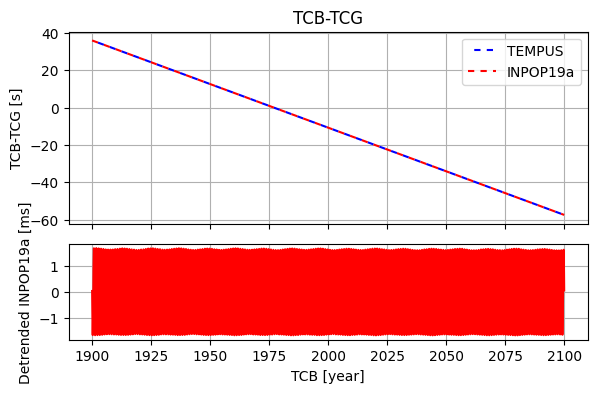

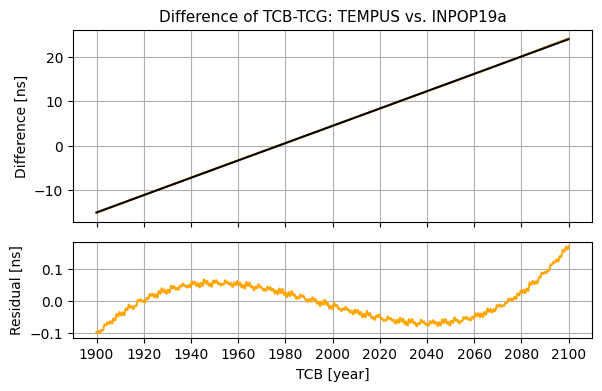

Drift slope (s/s): 6.187504137733727e-18
Average drift per day (ps/day): 0.534600357500194
Average drift per century (ns/cy): 19.52627805769459
Min and Max of detrended TCB-TCG (ns): -0.1019, 0.1727


In [ ]:
c = read_csv(out_csv)[0]
et = c["SecondsPastJ2000"]

tempus   = -c["TCB_minus_TCX"]            # TEMPUS writes TCB-TCX; INPOP stores TCG-TCB
internal = c["TCG_minus_TCB"]

residual(tempus, internal, et, "INPOP19a, 200 yr, planets only")

plot_compare_2timescales(et, tempus, "TEMPUS", internal, "INPOP19a",
                         label="TCB-TCG", x_tick=20, paper_mode=True,
                         save_as=str(figdir / "tcg200_klionerlike_inpop.pdf"))

### Versus PN1

Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -35.983421731282299 s)
Approx. mean drift (TCB-TCX): 1.279434 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb03_19a_earth_200yr_pn1.csv


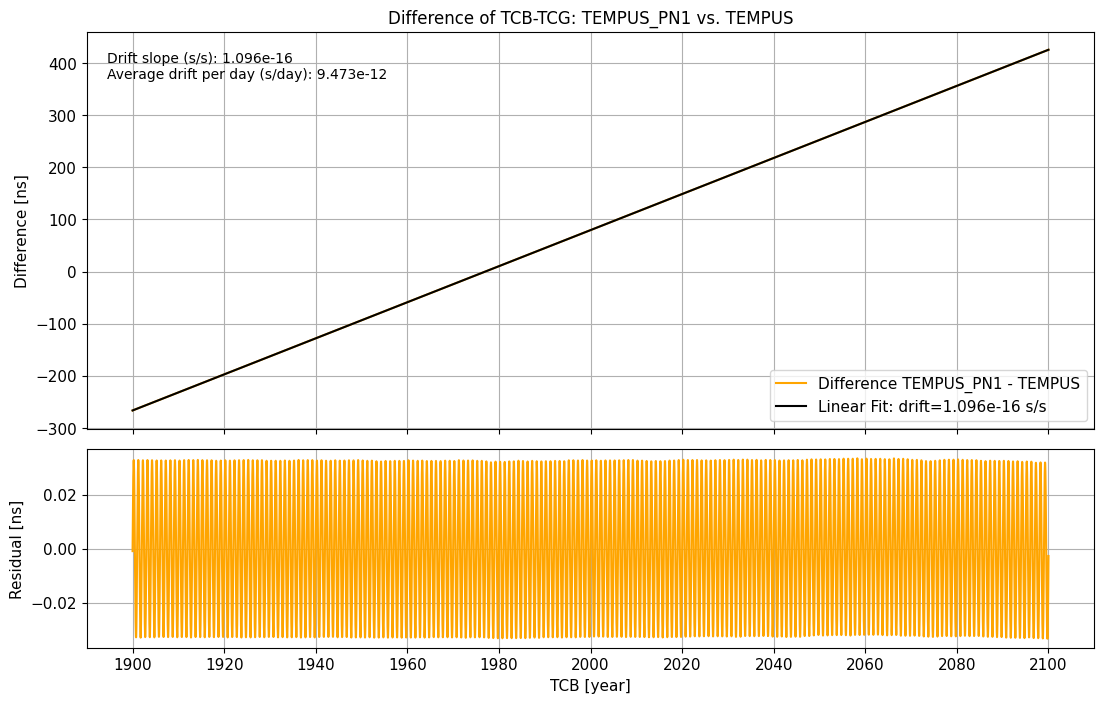

Drift slope (s/s): 1.0963746240712615e-16
Average drift per day (ps/day): 9.4726767519757
Average drift per century (ns/cy): 345.98951836591243
Min and Max of detrended TCB-TCG (ns): -0.0334, 0.0335


In [4]:
out_csv = Path("../output/nb03_19a_earth_200yr_pn1.csv").resolve()

run_tempus_integration(
    eph_19a_tcb, start, end, jd_step=0.75, out=out_csv,
    target="EARTH_CENTER", center="SSB", ext="auto",
    integrator="am12", out_tcg_tcb=True, zero=True, pn1=True,
);

tempus_pn1 = read_csv(out_csv)[0]["TCB_minus_TCX"]  

plot_compare_2timescales(et, -tempus_pn1, "TEMPUS_PN1", tempus, "TEMPUS",
                         label="TCB-TCG", x_tick=20, overview=False)

## 2 · Closing the gap: with asteroid perturbers 
The count is set by data availability, not by choice: the file carries 416 objects and TEMPUS includes every one whose
GM can be resolved — 350 for INPOP19a, 353 for INPOP21a.

In [ ]:
for eph, gm_header, tag in [(eph_19a_tcb, ast_gm_19a, "19a"), (eph_21a_tcb, ast_gm_21a, "21a")]:
    for kind in ("planets only", "+ small bodies"):
        out_csv = Path(f"../output/nb03_{tag}_earth_200yr"
                       f"{'_ast' if kind.startswith('+') else ''}.csv").resolve()
        asteroids = dict(asteroid_file=ast_file, asteroid_gm_header=gm_header) if kind.startswith("+") else {}

        if out_csv.is_file():
                print(f"Already have {out_csv.name}")
        else:
            run_tempus_integration(
                eph, start, end, jd_step=0.75, out=out_csv,
                target="EARTH_CENTER", center="SSB", ext="auto",
                integrator="am12", out_tcg_tcb=True, zero=True,**asteroids,
            )

        c = read_csv(out_csv)[0]
        tempus   = -c["TCB_minus_TCX"]
        internal = c["TCG_minus_TCB"]
        
        residual(tempus, internal, c["SecondsPastJ2000"], f"INPOP{tag}, 200 yr, {kind}")
        print(40 * "-")

Already have nb03_19a_earth_200yr.csv
INPOP19a, 200 yr, planets only             +6.188e-18 s/s (  +19.53 ns/cy)  peak 0.1727 ns
----------------------------------------
Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
Loaded GM header 'header_mba.19a': 350 new (header values take priority).
Skipped 20 asteroids without GM constants.
Using 353 auto-discovered asteroids (positions + GM available).
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -35.983422012881441 s)
Approx. mean drift (TCB-TCX): 1.279434 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb03_19a_earth_200yr_ast.csv
INPOP19a, 200 yr, + small bodies           -6.058e-21 s/s (   -0.02 ns/cy)  peak 0.0107 ns
----------------------------------------
Ephemeris version: INPOP21A
CALCEPH timescale: 2 (TCB)
  zeroed: TCB_minus_TCX = 0 at JD 2443144 + 0.5003725 (TCB) (shift -35.983421997883589 s)
Approx. mean drift (TCB-TCX): 1.279434 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS

In [6]:
f19 = results["INPOP19a, 200 yr, planets only"][0] / results["INPOP19a, 200 yr, + small bodies"][0]
f21 = results["INPOP21a, 200 yr, planets only"][0] / results["INPOP21a, 200 yr, + small bodies"][0]
print(f"the small bodies improve INPOP19a by {f19:.0f}x, INPOP21a by only {f21:.1f}x")

the small bodies improve INPOP19a by -1021x, INPOP21a by only 1.4x


In [7]:
GM_E, AU, C = 3.986004418e14, 1.495978707e11, 299792458.0   # m^3/s^2, m, m/s
M_ring = 0.0259                                              # Earth masses (Fienga et al. 2021b)

# a ring seen from well inside it is a near-constant potential: U/c^2 = G M / (r c^2)
for r_au in (39.3, 0.5 * (39.3 + 47.6), 47.6):
    print(f"ring at {r_au:5.2f} AU : U/c^2 = {M_ring * GM_E / (r_au * AU * C**2):.3e} s/s")

observed = results["INPOP21a, 200 yr, + small bodies"][0]
u_mid = M_ring * GM_E / (0.5 * (39.3 + 47.6) * AU * C**2)
print(f"observed INPOP21a drift       : {observed:.3e} s/s")
print(f"mid-band U/c^2 vs observed    : {abs(u_mid / abs(observed) - 1) * 100:.1f} %")

ring at 39.30 AU : U/c^2 = 1.954e-17 s/s
ring at 43.45 AU : U/c^2 = 1.767e-17 s/s
ring at 47.60 AU : U/c^2 = 1.613e-17 s/s
observed INPOP21a drift       : 1.760e-17 s/s
mid-band U/c^2 vs observed    : 0.4 %


The asymmetry is the substantive result. For INPOP19a the discrete asteroids all but close the gap, and if INPOP19a has a ring that is used for the EOM, it doesn't factor into the INPOP internal calculation of the time-scale, only the descrete asteroids; for INPOP21a they barely help. This is most likely due to the fact that INPOP21a includes 500 individually integrated objects (Fienga et al. 2021b), that amount to a quoted total mass of 0.0259 M_⊕ between 39.3 and 47.6 AU. That mass contributes a near-constant potential at the Earth of U/c^2 = 1.8e−17 – matching the above observed differential drift w.r.t. INPOP21a to better than 2%.

Below the same plots as in 1. but for the remaining 3 integrations.

TEMPUS + 353 small bodies linear drift: -1.4808266059990602e-08 s/s, -1.279434187583188 ms/day
INPOP19a linear drift: -1.4808266059984549e-08 s/s, -1.279434187582665 ms/day
Detrended INPOP19a min/max: -1.682e-03, 1.703e-03 s


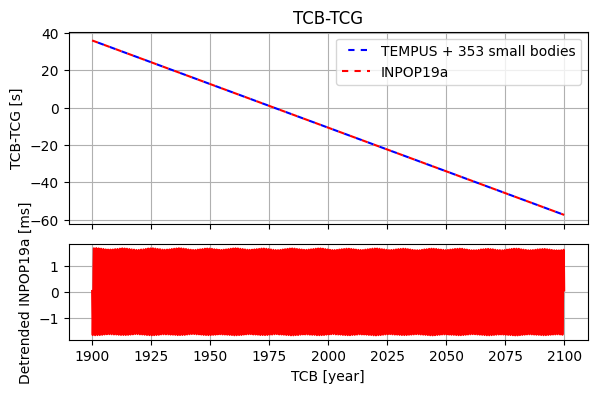

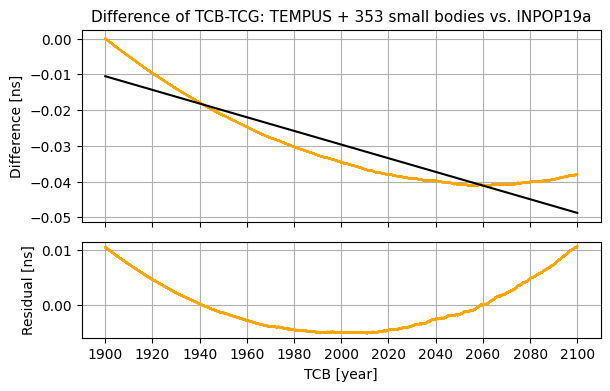

Drift slope (s/s): -6.0576095087787014e-21
Average drift per day (ps/day): -0.0005233774615584798
Average drift per century (ns/cy): -0.019116361783423477
Min and Max of detrended TCB-TCG (ns): -0.0051, 0.0107


In [8]:
c = read_csv(Path("../output/nb03_19a_earth_200yr_ast.csv").resolve())[0]
tempus   = -c["TCB_minus_TCX"]
internal = c["TCG_minus_TCB"]
tempus   = tempus - tempus[0] + internal[0]

plot_compare_2timescales(c["SecondsPastJ2000"], tempus, "TEMPUS + 353 small bodies",
                         internal, "INPOP19a", label="TCB-TCG", x_tick=20,
                         paper_mode=True, save_as=str(figdir / "tcg24_inpop19a_353ast.pdf"))

TEMPUS + 353 small bodies linear drift: -1.4808266060443166e-08 s/s, -1.2794341876222894 ms/day
INPOP21a linear drift: -1.480826607803957e-08 s/s, -1.2794341891426189 ms/day
Detrended INPOP21a min/max: -1.682e-03, 1.703e-03 s


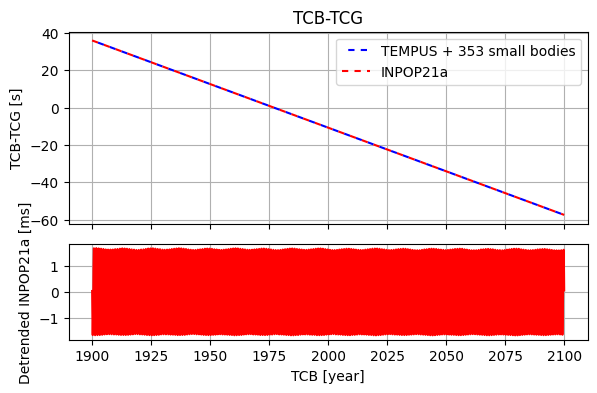

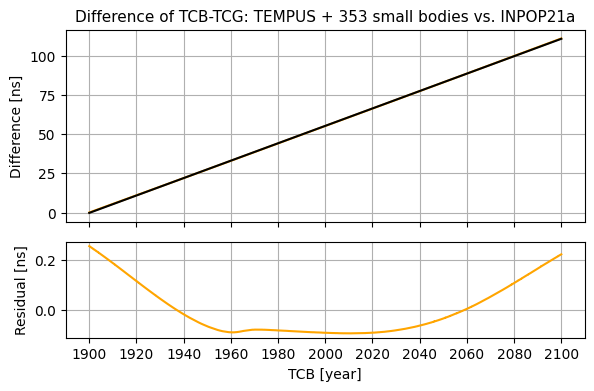

Drift slope (s/s): 1.7596409955171168e-17
Average drift per day (ps/day): 1.520329820126789
Average drift per century (ns/cy): 55.53004668013097
Min and Max of detrended TCB-TCG (ns): -0.0957, 0.2544


In [9]:
c = read_csv(Path("../output/nb03_21a_earth_200yr_ast.csv").resolve())[0]
tempus   = -c["TCB_minus_TCX"]
internal = c["TCG_minus_TCB"]
tempus   = tempus - tempus[0] + internal[0]

plot_compare_2timescales(c["SecondsPastJ2000"], tempus, "TEMPUS + 353 small bodies",
                         internal, "INPOP21a", label="TCB-TCG", x_tick=20,
                         paper_mode=True, save_as=str(figdir / "tcg_inpop21a_353ast.pdf")
                         )

TEMPUS + planets only linear drift: -1.4808266053878073e-08 s/s, -1.2794341870550656 ms/day
INPOP21a internal linear drift: -1.480826607803957e-08 s/s, -1.2794341891426189 ms/day
Detrended INPOP21a internal min/max: -1.682e-03, 1.703e-03 s


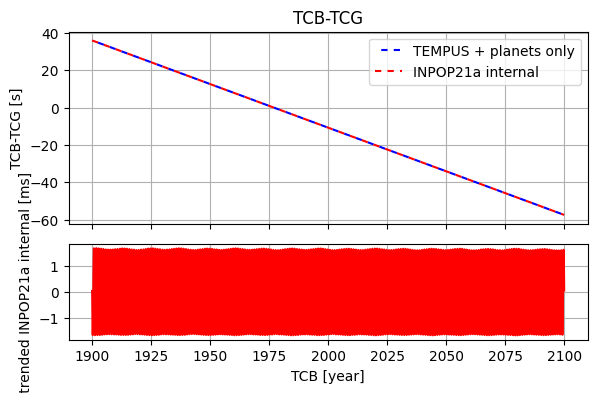

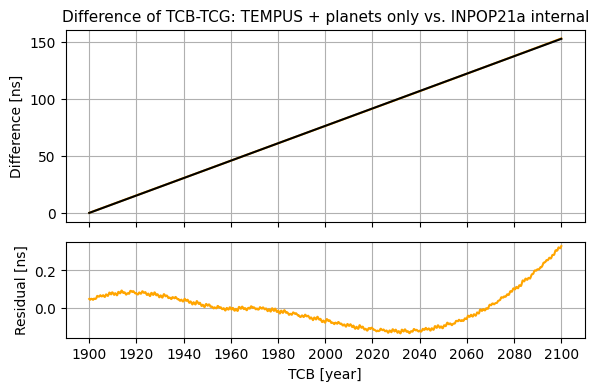

Drift slope (s/s): 2.416151370150169e-17
Average drift per day (ps/day): 2.087554783809746
Average drift per century (ns/cy): 76.24793847865097
Min and Max of detrended TCB-TCG (ns): -0.1386, 0.3311


In [10]:
c = read_csv(Path("../output/nb03_21a_earth_200yr.csv").resolve())[0]
tempus   = -c["TCB_minus_TCX"]
tempus   = tempus - tempus[0] + internal[0]

plot_compare_2timescales(c["SecondsPastJ2000"], tempus, "TEMPUS + planets only",
                         internal, "INPOP21a internal", label="TCB-TCG", x_tick=20,
                         paper_mode=True, save_as=str(figdir / "tcg_inpop21a.pdf")
                         )

## 3 · TDB vs TCB flavour of the same release

A pure consistency check of TEMPUS: the same INPOP19a solution, distributed in two timescale
flavours, must give the same TCB−TCG at the same physical epochs. It exercises the
1/(1−L_B) rescaling of positions and GM and the matching chain-rule factor on the integrand.

Both runs are anchored on the same TT epochs, so they begin and end on the same physical
events. The step must also be matched: a uniform TCB grid of 0.75 d maps exactly onto a uniform
TDB grid of 0.75(1−L_B) d. Stepping both files by 0.75 d in their own scale would instead let
the grids walk ~12 s apart over 24 yr and manufacture a ~10⁻¹⁶ s/s drift out of nothing.

Ephemeris version: INPOP19A
CALCEPH timescale: 2 (TCB)
  Converted TDB input grid to TCB (IAU 2006 B3, L_B=1.550519768000e-08); native TCB step: 0.7500000116288984 d
Approx. mean drift (TCB-TCX): 1.279435 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb03_19aTCB_earth_100yr.csv
Ephemeris version: INPOP19A
CALCEPH timescale: 1 (TDB)
Approx. mean drift (TCB-TCX): 1.279435 ms/day
Wrote /home/yan/PythonWorkdir/CNRS_Release/TEMPUS/output/nb03_19aTDB_earth_100yr.csv
INPOP19a TCB vs TDB                        +1.930e-23 s/s (   +0.00 ns/cy)  peak 0.0592 ps
----------------------------------------
Epochs match within 9.59 ps



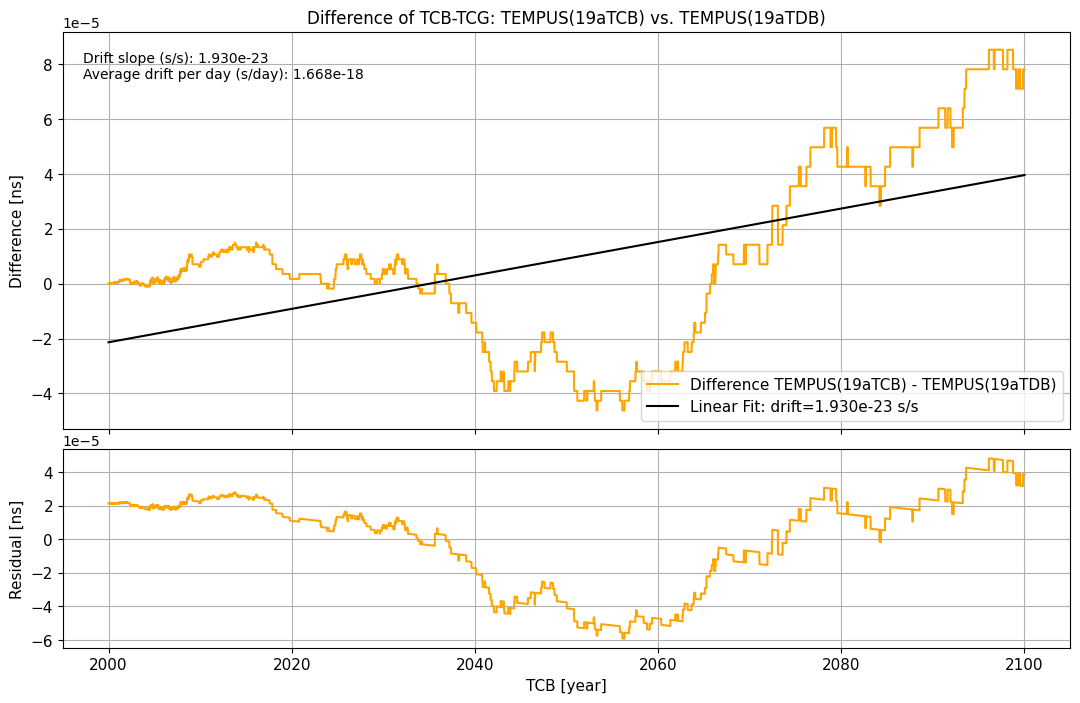

Drift slope (s/s): 1.9304532509351832e-23
Average drift per day (ps/day): 1.6679116088079984e-06
Average drift per century (ns/cy): 6.0920471511712134e-05
Min and Max of detrended TCB-TCG (ns): -0.0001, 0.0000


In [11]:
start_tt, end_tt = J2000_TT, J2000_TT + 36525
start_tdb = jd_tt_to_tdb(*jd_split(start_tt), eph_19a_tdb)
end_tdb   = jd_tt_to_tdb(*jd_split(end_tt),   eph_19a_tdb)

for eph, tag in [(eph_19a_tcb, "TCB"), (eph_19a_tdb, "TDB")]:

    out_csv = Path(f"../output/nb03_19a{tag}_earth_100yr.csv").resolve()

    run_tempus_integration(
        eph, start_tdb, end_tdb, jd_step=0.75, out=out_csv,
        target="EARTH_CENTER", center="SSB", ext="auto",
        input_jd_are_tdb=True,
    );

    if tag=="TCB":
        c_tcb = read_csv(out_csv)[0]
    else:
        c_tdb = read_csv(out_csv)[0]

n = min(len(c_tcb["JD_int"]), len(c_tdb["JD_int"]))
et = c_tcb["SecondsPastJ2000"][:n]

residual(c_tcb["TCB_minus_TCX"][:n], c_tdb["TCB_minus_TCX"][:n], et, f"INPOP19a TCB vs TDB", unit="ps")
print(40 * "-")

# the grids really are the same physical events, not merely the same row count
g = jd_tcb_to_tdb(TimeGrid(c_tcb["JD_int"][:n], c_tcb["JD_frac"][:n]))
off = ((g.jd_int - c_tdb["JD_int"][:n]) + (g.jd_frac - c_tdb["JD_frac"][:n])) * DAY_S
print(f"Epochs match within {np.max(np.abs(off))*1e12:.2f} ps\n")

plot_compare_2timescales(et, 
        c_tcb["TCB_minus_TCX"][:n], "TEMPUS(19aTCB)",
        c_tdb["TCB_minus_TCX"][:n], "TEMPUS(19aTDB)",
        label=f"TCB-TCG", overview=False, x_tick=20)

## 5 · Summary — the numbers used in the paper

In [12]:
print(f"{'comparison':42s} {'drift [s/s]':>13s} {'ns/cy':>9s} {'peak':>13s}")
print("-" * 80)
for label, (drift, peak, unit) in results.items():
    print(f"{label:42s} {drift:13.6e} {drift/NS_CY:9.2f} "
          f"{peak * (1e12 if unit == 'ps' else 1e9):10.3f} {unit}")

comparison                                   drift [s/s]     ns/cy          peak
--------------------------------------------------------------------------------
INPOP19a, 200 yr, planets only              6.187504e-18     19.53      0.173 ns
INPOP19a, 200 yr, + small bodies           -6.057610e-21     -0.02      0.011 ns
INPOP21a, 200 yr, planets only              2.416151e-17     76.25      0.331 ns
INPOP21a, 200 yr, + small bodies            1.759641e-17     55.53      0.254 ns
INPOP19a TCB vs TDB                         1.930453e-23      0.00      0.059 ps
